# 06 Baseline และโมเดลผู้สมัคร 3 ตระกูล (Poisson / Random Forest / HistGradientBoosting)

> **โหมดวิจัยย้อนหลังแบบมีเงื่อนไขเท่านั้น** — `research_mode = retrospective_conditional_research`, `production_enabled = False`
> - หน่วยคือ จังหวัดที่รายงาน × วัน (ไม่ใช่สายทาง) และ **ไม่ใช่** การพยากรณ์ล่วงหน้าที่พิสูจน์แล้วว่าข้อมูลพร้อมใช้ ณ เวลาออกพยากรณ์
> - `training_eligible` เป็นตัวกรองออฟไลน์ที่รู้หลังเห็นปัญหาคุณภาพข้อมูล (อาจขึ้นกับผลลัพธ์) การกรองด้วยมันจึงก่อ **selection bias** คะแนนทุกตัวอธิบายเฉพาะเซลล์ที่ถูกเลือก ไม่ใช่ทั้งปีหรือทุกถนน
> - ความพร้อมของโมเดลจริงยัง **BLOCKED** (วันที่กำกวม, ความล่าช้าการรายงาน, การ map จังหวัด, หน่วยสายทาง) และผลนี้ **ไม่ใช่** ความเสี่ยงอุบัติเหตุรายบุคคล

**เป้าหมาย:** เปรียบเทียบ Baseline 4 แบบกับโมเดลจริง 3 ตระกูลที่ต่างกันตาม `workflow/model-protocol-v1.md` (ล็อกก่อน fit) ด้วย backtest ตามเวลา 4 fold ภายใน Train เท่านั้น แล้วล็อกการเลือกจาก OOF ก่อนฝึกบน eligible Train ทั้งหมด

**อินพุต (อ่านอย่างเดียว ตรวจ SHA256 ก่อนใช้):** ใต้ `ROADAWARE_DATA_ROOT` (ค่าเริ่มต้น `backend/`): `data/processed/province_day_panel.csv`, manifest สามชั้น (source → interim → split) และ `reports/data/leakage/leakage_audit.json` + `readiness_summary.json`; config `backend/config/model_experiment_v1.json` ซึ่งต้องตรงกับ `PROTOCOL_LOCK` ในเซลล์ FUNCTIONS

**ขั้นตอน:**
1. ตรวจ lineage ของข้อมูล, ผลการตรวจ leakage ที่ทำไว้ และสัญญา data/config เมื่อรันซ้ำ (ไม่บังคับให้ readiness เป็น true)
2. ตาราง support ราย split × เดือน ครบทุกเดือนรวมเดือนที่ไม่มีแถว eligible — เป็นการนับเท่านั้น ไม่ประเมินโมเดลบนปี 2024/2025
3. สร้าง 4 fold แบบ expanding window: fit ด้วยแถว eligible ใน Train ที่ `target_end <= เวลาออกพยากรณ์แรกของ fold`
4. fit Baseline 4 แบบ + 7 configuration ของโมเดล (Poisson 3, RF 2, HGB 2) ในทุก fold; encoder/ค่าเฉลี่ยทุกตัว fit จาก Train ของ fold นั้น
5. คำนวณ metric บน OOF ซึ่งเป็นเซลล์ชุดเดียวกันทุกวิธี
6. เลือก configuration ดีที่สุดต่อตระกูล → selected candidate → เทียบกับ baseline ที่แข็งที่สุดด้วยเกณฑ์ที่ล็อกไว้ + paired block bootstrap แล้วบันทึก `selection_lock.json`
7. หลังล็อกแล้วจึง fit ทุก configuration บน eligible Train ทั้งหมด บันทึก bundle และตรวจว่าโหลดกลับมาทำนายได้ค่าเดิม
8. บันทึก manifest (hash ของอินพุต/โปรโตคอล/config/source/bundle/prediction)

**การตรวจ:** config ตรงโปรโตคอล, feature = allowlist, ขอบป้ายกำกับของแต่ละ fold, key ไม่ซ้อนกัน, prediction/label ต้อง finite และไม่ติดลบ, configuration ที่ล้มเหลว/ไม่ converge ถูกตัดสิทธิ์อย่างชัดแจ้ง, การเลือกใช้เฉพาะ OOF, lock ไม่เปลี่ยนหลังฝึกบน Train ทั้งหมด

**ข้อจำกัด:** Bootstrap เป็นการสำรวจ ไม่ปรับสำหรับการเลือกโมเดล; ไม่มี lag/สภาพอากาศ/วันหยุด/การจราจร; ปี 2025 เคยถูกดูมาแล้ว; Notebook นี้ **ไม่** ให้คะแนนปี 2024/2025 (เป็นงานของ 07/08)

**ผลลัพธ์จริง:** ตาราง/กราฟด้านล่างแสดงหลังรันเท่านั้น ถ้า notebook ยังไม่มี output แปลว่ายังไม่ได้รัน

In [1]:
# FUNCTIONS (notebook 06) - self-contained; tests and notebooks 07/08 execute this cell directly
import hashlib, json, math, os, time, warnings
from pathlib import Path
import numpy as np, pandas as pd

BUNDLE_FORMAT = 'roadaware_model_bundle_v1'
LOCK_FORMAT = 'roadaware_selection_lock_v1'
TARGET = 'y_recorded_count'
KEYS = ['province', 'target_date']
OOF_SCOPE = 'oof_train_backtest'
EXPERIMENT_CONFIG_NAME = 'model_experiment_v1.json'
PANEL_PATH = 'data/processed/province_day_panel.csv'
DATA_FOUNDATION_PATHS = {
    'source_manifest': 'data/raw/accidents/source_manifest.json',
    'artifact_manifest': 'data/interim/artifact_manifest.json',
    'split_manifest': 'data/processed/split_artifact_manifest.json',
    'leakage_audit': 'reports/data/leakage/leakage_audit.json',
    'readiness_summary': 'reports/data/leakage/readiness_summary.json',
}
METRIC_KEYS = ['n_rows', 'weight_sum', 'observed_total', 'predicted_total', 'mae', 'rmse', 'bias', 'wape',
               'mean_poisson_deviance', 'n_floored_for_deviance']
CAVEATS = [
    'Retrospective conditional research on reported province-days; not the route model and not a verified as-of forecast.',
    'training_eligible is an offline quality filter known after observing problems (may depend on outcomes); conditioning on it introduces selection bias.',
    'Scores describe the selected eligible cells only, not complete annual or road coverage.',
    'Final model readiness remains BLOCKED (date ambiguity, reporting availability, province mapping, route unit).',
    'Not a personal crash probability; production is disabled.',
    '2025 was seen before; neither 2024 nor 2025 is an independent untouched test.',
]

# Locked values from workflow/model-protocol-v1.md; config/model_experiment_v1.json must match exactly.
PROTOCOL_LOCK = {
    'research_mode': 'retrospective_conditional_research',
    'production_enabled': False,
    'target': 'y_recorded_count',
    'features': ['province', 'day_of_week', 'month', 'day_of_month', 'day_of_year', 'is_weekend'],
    'cohort': {'split': 'train', 'eligibility_column': 'training_eligible'},
    'folds': [{'fold': 1, 'eval_start': '2022-01-01', 'eval_end': '2022-06-30'},
              {'fold': 2, 'eval_start': '2022-07-01', 'eval_end': '2022-12-31'},
              {'fold': 3, 'eval_start': '2023-01-01', 'eval_end': '2023-06-30'},
              {'fold': 4, 'eval_start': '2023-07-01', 'eval_end': '2023-12-31'}],
    'baselines': [
        {'id': 'baseline_zero', 'family': 'baseline', 'kind': 'zero', 'deviance_domain': 'undefined', 'params': {}},
        {'id': 'baseline_global_mean', 'family': 'baseline', 'kind': 'global_mean', 'deviance_domain': 'floor', 'params': {}},
        {'id': 'baseline_province_mean', 'family': 'baseline', 'kind': 'province_mean', 'deviance_domain': 'floor', 'params': {}},
        {'id': 'baseline_province_weekday_k10', 'family': 'baseline', 'kind': 'province_weekday_smoothed', 'deviance_domain': 'floor',
         'params': {'pseudo_obs': 10}}],
    'candidates': [
        {'id': 'poisson_alpha_1e-4', 'family': 'poisson', 'deviance_domain': 'floor', 'params': {'alpha': 0.0001, 'max_iter': 1000, 'tol': 1e-06}},
        {'id': 'poisson_alpha_1e-2', 'family': 'poisson', 'deviance_domain': 'floor', 'params': {'alpha': 0.01, 'max_iter': 1000, 'tol': 1e-06}},
        {'id': 'poisson_alpha_1e0', 'family': 'poisson', 'deviance_domain': 'floor', 'params': {'alpha': 1.0, 'max_iter': 1000, 'tol': 1e-06}},
        {'id': 'rf_t80_d12_l64_m50', 'family': 'random_forest', 'deviance_domain': 'floor',
         'params': {'n_estimators': 80, 'max_depth': 12, 'max_leaf_nodes': 64, 'min_samples_leaf': 50, 'max_features': 0.7,
                    'criterion': 'poisson', 'random_state': 42, 'n_jobs': 2}},
        {'id': 'rf_t120_d16_l128_m100', 'family': 'random_forest', 'deviance_domain': 'floor',
         'params': {'n_estimators': 120, 'max_depth': 16, 'max_leaf_nodes': 128, 'min_samples_leaf': 100, 'max_features': 0.7,
                    'criterion': 'poisson', 'random_state': 42, 'n_jobs': 2}},
        {'id': 'hgb_i120_l15_m50_r1', 'family': 'hist_gradient_boosting', 'deviance_domain': 'floor',
         'params': {'max_iter': 120, 'max_leaf_nodes': 15, 'min_samples_leaf': 50, 'l2_regularization': 1.0, 'learning_rate': 0.05,
                    'loss': 'poisson', 'early_stopping': False, 'random_state': 42}},
        {'id': 'hgb_i160_l31_m100_r5', 'family': 'hist_gradient_boosting', 'deviance_domain': 'floor',
         'params': {'max_iter': 160, 'max_leaf_nodes': 31, 'min_samples_leaf': 100, 'l2_regularization': 5.0, 'learning_rate': 0.05,
                    'loss': 'poisson', 'early_stopping': False, 'random_state': 42}}],
    'encoding': {
        'poisson': {'onehot': ['province', 'day_of_week', 'month', 'day_of_month', 'day_of_year', 'is_weekend'], 'passthrough': []},
        'random_forest': {'onehot': ['province', 'day_of_week', 'month', 'is_weekend'], 'passthrough': ['day_of_month', 'day_of_year']},
        'hist_gradient_boosting': {'ordinal_categorical': ['province', 'day_of_week', 'month', 'is_weekend'],
                                   'passthrough': ['day_of_month', 'day_of_year'], 'unknown_value': -1}},
    'family_tie_order': ['poisson', 'random_forest', 'hist_gradient_boosting'],
    'metrics': {'primary': 'mean_poisson_deviance', 'deviance_floor': 1e-09},
    'decision_gate': {'min_relative_deviance_improvement': 0.01, 'max_mae_ratio': 1.02, 'min_folds_improved': 3, 'bootstrap_ci_upper_below': 0.0},
    'bootstrap': {'block_days': 7, 'replicates': 500, 'seed': 42, 'ci_level': 0.95},
    'threads': 2,
}

# ---------------------------------------------------------------- hashing / strict JSON / config
def canonical_json(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False, separators=(',', ':'), allow_nan=False)

def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

def sha256_json(obj):
    return sha256_bytes(canonical_json(to_jsonable(obj)).encode('utf-8'))

def to_jsonable(obj):
    """Recursively convert to strict JSON types: NaN/NaT/None -> null (undefined), +-inf -> error."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if obj is None or obj is pd.NaT:
        return None
    if isinstance(obj, (bool, np.bool_)):
        return bool(obj)
    if isinstance(obj, (int, np.integer)):
        return int(obj)
    if isinstance(obj, (float, np.floating)):
        v = float(obj)
        if math.isnan(v):
            return None
        if math.isinf(v):
            raise ValueError('non-finite value cannot be written to strict JSON')
        return v
    if isinstance(obj, pd.Timestamp):
        return obj.isoformat()
    if isinstance(obj, (str, Path)):
        return str(obj)
    raise TypeError('not JSON-serialisable: ' + type(obj).__name__)

def write_json(path, obj):
    Path(path).write_text(json.dumps(to_jsonable(obj), ensure_ascii=False, indent=2, allow_nan=False), 'utf-8')

def records(df):
    return [to_jsonable(r) for r in df.to_dict('records')]

def validate_experiment_config(cfg, lock=PROTOCOL_LOCK):
    """Return the locked keys whose config value differs from the protocol (empty list = config matches)."""
    out = []
    for k, v in lock.items():
        if k not in cfg:
            out.append(k + ': missing from config')
        elif canonical_json(cfg[k]) != canonical_json(v):
            out.append(k + ': differs from the locked protocol value')
    ids = [s.get('id') for s in list(cfg.get('baselines', [])) + list(cfg.get('candidates', []))]
    if len(ids) != len(set(ids)):
        out.append('spec ids are not unique')
    return out

def find_backend_root(start=None):
    env = os.environ.get('ROADAWARE_BACKEND_ROOT')
    if env:
        return Path(env).resolve()
    here = Path(start or Path.cwd()).resolve()
    for c in [here, *here.parents]:
        if (c / 'backend' / 'config' / EXPERIMENT_CONFIG_NAME).is_file():
            return c / 'backend'
        if c.name == 'backend' and (c / 'config' / EXPERIMENT_CONFIG_NAME).is_file():
            return c
    raise FileNotFoundError('backend/config/' + EXPERIMENT_CONFIG_NAME + ' not found from ' + str(here) + '; open the repository root or backend/notebooks')

def _cell_source(c):
    return ''.join(c['source']) if isinstance(c['source'], list) else c['source']

def notebook_semantic_sha256(path):
    """Hash of cell types + sources only (outputs, execution counts and metadata excluded)."""
    nb = json.loads(Path(path).read_text('utf-8'))
    return sha256_json([{'cell_type': c['cell_type'], 'source': _cell_source(c)} for c in nb['cells']])

def functions_cell_source(path):
    nb = json.loads(Path(path).read_text('utf-8'))
    hits = [_cell_source(c) for c in nb['cells'] if c['cell_type'] == 'code' and _cell_source(c).lstrip().startswith('# FUNCTIONS')]
    if len(hits) != 1:
        raise ValueError(str(path) + ': expected exactly one FUNCTIONS cell')
    return hits[0]

def package_versions():
    import platform, sklearn, scipy, joblib, threadpoolctl, matplotlib
    return {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'scipy': scipy.__version__, 'joblib': joblib.__version__, 'threadpoolctl': threadpoolctl.__version__, 'matplotlib': matplotlib.__version__}

# ---------------------------------------------------------------- data-foundation verification / rerun contract
def _audit_hashes(base, entries):
    out = []
    for e in entries:
        p = Path(base) / e['path']
        if not p.is_file():
            out.append('missing ' + e['path'])
        elif sha256_file(p) != e['sha256']:
            out.append('sha256 mismatch ' + e['path'])
    return out

def verify_data_foundation(data_root):
    """Re-verify the chained source/interim/split manifests, the panel hash and that the leakage audit ran on these
    exact manifests with all implemented checks passing. Readiness is reported, NOT required to be true.
    Returns (report, violations); violations is a dict of failed checks."""
    root = Path(data_root)
    missing = [rel for rel in list(DATA_FOUNDATION_PATHS.values()) + [PANEL_PATH] if not (root / rel).is_file()]
    if missing:
        raise FileNotFoundError('data foundation incomplete under ' + str(root) + ': ' + ', '.join(missing) + '; run notebooks 01-05 first')
    J = {k: json.loads((root / rel).read_text('utf-8')) for k, rel in DATA_FOUNDATION_PATHS.items()}
    H = {rel: sha256_file(root / rel) for rel in DATA_FOUNDATION_PATHS.values()}
    H[PANEL_PATH] = sha256_file(root / PANEL_PATH)
    man, art, sman, la, rs = (J[k] for k in ('source_manifest', 'artifact_manifest', 'split_manifest', 'leakage_audit', 'readiness_summary'))
    chained = [DATA_FOUNDATION_PATHS[k] for k in ('source_manifest', 'artifact_manifest', 'split_manifest')]
    la_in = la.get('input_sha256', {})
    failed_checks = [c.get('check') for c in la.get('checks', []) if not c.get('passed')]
    checks = {
        'raw_snapshots_vs_source_manifest': _audit_hashes(root, man.get('files', [])) or ([] if man.get('files') else ['no files listed']),
        'interim_vs_artifact_manifest': _audit_hashes(root, art.get('files', [])) or ([] if art.get('files') else ['no files listed']),
        'artifact_manifest_built_from_current_source_manifest': [] if art.get('input_source_manifest_sha256') == H[chained[0]] else ['artifact manifest does not reference the current source manifest'],
        'split_inputs_lineage': _audit_hashes(root, sman.get('inputs', [])) or ([] if sman.get('inputs') else ['no inputs listed']),
        'split_outputs_vs_split_manifest': _audit_hashes(root, sman.get('files', [])),
        'panel_listed_in_split_manifest': [] if any(e.get('path') == PANEL_PATH and e.get('sha256') == H[PANEL_PATH] for e in sman.get('files', [])) else ['panel hash not listed in split manifest'],
        'leakage_audit_ran_on_current_manifests': ['leakage input differs: ' + k for k in chained if la_in.get(k) != H[k]],
        'leakage_implemented_checks_all_passed': (['failed: ' + str(c) for c in failed_checks] + (['no checks recorded'] if not la.get('checks') else [])
                                                  + (['readiness lists failed checks'] if rs.get('software_checks_failed') else [])),
        'leakage_negative_controls_all_caught': [] if rs.get('negative_controls_total', 0) > 0 and rs.get('negative_controls_caught') == rs.get('negative_controls_total') else ['negative controls not all caught'],
        'readiness_summary_matches_leakage_audit': [] if canonical_json(la.get('readiness')) == canonical_json(rs) else ['readiness_summary.json differs from leakage_audit.json'],
    }
    report = {'hashes': H, 'checks': {k: {'passed': not v, 'violations': v[:5]} for k, v in checks.items()},
              'final_model_readiness': rs.get('final_model_readiness'), 'unresolved_blockers': rs.get('unresolved_blockers'),
              'claim_scope': rs.get('claim_scope')}
    return report, {k: v for k, v in checks.items() if v}

def experiment_contract(data_report, protocol_sha, experiment_config_sha, data_pipeline_config_sha):
    """Data/config contract of an output root; reruns into the same root must reproduce it exactly."""
    return {'data_inputs_sha256': dict(sorted(data_report['hashes'].items())), 'protocol_sha256': protocol_sha,
            'experiment_config_sha256': experiment_config_sha, 'data_pipeline_config_sha256': data_pipeline_config_sha}

def check_rerun_contract(manifest_path, contract):
    p = Path(manifest_path)
    if not p.is_file():
        return 'new_output_root'
    prev = json.loads(p.read_text('utf-8')).get('contract')
    if prev is None:
        raise RuntimeError('refusing: ' + str(p) + ' has no recorded contract; use a new output dir')
    if canonical_json(prev) != canonical_json(contract):
        diff = sorted(k for k in set(prev) | set(contract) if canonical_json(prev.get(k)) != canonical_json(contract.get(k)))
        raise RuntimeError('refusing to overwrite model outputs built from a different data/config contract (' + ', '.join(diff) + '); use a new --output-dir')
    return 'same_contract_rerun'

# ---------------------------------------------------------------- panel / features / validation
def as_bool(s):
    if s.dtype == bool:
        return s
    m = s.astype(str).str.strip().str.lower().map({'true': True, 'false': False, '1': True, '0': False})
    if m.isna().any():
        raise ValueError('non-boolean values in ' + str(s.name))
    return m.astype(bool)

def load_panel(path):
    p = pd.read_csv(path, keep_default_na=False, dtype={'province': str, 'flag_reasons': str, 'flag_scope': str})
    p['target_date'] = pd.to_datetime(p['target_date'])
    for c in ('issue_time', 'target_start', 'target_end'):
        p[c] = pd.to_datetime(p[c])
    for c in ('training_eligible', 'possibly_undercounted', 'boundary_excluded'):
        p[c] = as_bool(p[c])
    return p

def cohort(panel, split='train', eligibility='training_eligible'):
    """Eligible rows of one split (the same cells are used by every method)."""
    return panel[(panel['split'] == split) & as_bool(panel[eligibility])].copy()

def feature_frame(df, features):
    """Allowlisted inputs only: province as string, calendar fields as int64. Nothing else reaches a model."""
    missing = [f for f in features if f not in df.columns]
    if missing:
        raise KeyError('missing feature columns: ' + ', '.join(missing))
    X = pd.DataFrame(index=df.index)
    for f in features:
        if f == 'province':
            X[f] = df[f].astype(str)
        else:
            v = pd.to_numeric(df[f], errors='raise').astype(float)
            if not np.isfinite(v.to_numpy()).all():
                raise ValueError('non-finite values in feature ' + f)
            X[f] = v.astype('int64')
    return X

def _check_values(v, what):
    a = np.asarray(v, dtype=float).ravel()
    if not np.isfinite(a).all():
        raise ValueError('invalid ' + what + ': non-finite values')
    if (a < 0).any():
        raise ValueError('invalid ' + what + ': negative values')
    return a

def validate_labels(y):
    return _check_values(y, 'labels')

def validate_predictions(p):
    return _check_values(p, 'predictions')

# ---------------------------------------------------------------- metrics
def unit_poisson_deviance(y, mu):
    """2 * (y log(y/mu) - y + mu) with y log y = 0 at y = 0; mu must be > 0."""
    y, mu = np.asarray(y, float), np.asarray(mu, float)
    if (mu <= 0).any():
        raise ValueError('Poisson deviance needs strictly positive predicted means')
    ylog = np.zeros_like(y)
    pos = y > 0
    ylog[pos] = y[pos] * np.log(y[pos] / mu[pos])
    return 2.0 * (ylog - y + mu)

def regression_metrics(y, pred, weight=None, deviance_domain='floor', floor=1e-9):
    """Raw-prediction MAE/RMSE/bias/WAPE/totals; Poisson deviance with an explicit floor (count recorded), or null
    when deviance_domain='undefined' (exact-zero predictor). WAPE is null when the observed total is 0."""
    y, p = validate_labels(y), validate_predictions(pred)
    if len(y) != len(p):
        raise ValueError('labels and predictions differ in length')
    w = np.ones_like(y) if weight is None else _check_values(weight, 'weights')
    if len(w) != len(y):
        raise ValueError('weights differ in length')
    W = float(w.sum())
    out = dict.fromkeys(METRIC_KEYS)
    out.update(n_rows=int(len(y)), weight_sum=W, observed_total=float((w * y).sum()), predicted_total=float((w * p).sum()))
    if W <= 0:
        return out
    e = p - y
    abs_sum = float((w * np.abs(e)).sum())
    out['mae'] = abs_sum / W
    out['rmse'] = float(np.sqrt((w * e * e).sum() / W))
    out['bias'] = float((w * e).sum() / W)
    out['wape'] = None if out['observed_total'] == 0 else abs_sum / out['observed_total']
    if deviance_domain == 'floor':
        out['n_floored_for_deviance'] = int((p < floor).sum())
        out['mean_poisson_deviance'] = float((w * unit_poisson_deviance(y, np.maximum(p, floor))).sum() / W)
    elif deviance_domain != 'undefined':
        raise ValueError('unknown deviance_domain ' + str(deviance_domain))
    return out

# ---------------------------------------------------------------- temporal folds
def first_issue_time(eval_start, issue_hour, days_before, tz):
    return pd.Timestamp(eval_start, tz=tz) - pd.Timedelta(days=days_before) + pd.Timedelta(hours=issue_hour)

def fold_violations(fit, ev, cutoff, keys=KEYS):
    out = []
    if fit.empty:
        out.append('no fit rows')
    if ev.empty:
        out.append('no evaluation rows')
    n = int((fit['target_end'] > cutoff).sum()) if len(fit) else 0
    if n:
        out.append('%d fit labels end after the first evaluation issue %s' % (n, cutoff))
    if len(ev) and (ev['issue_time'] < cutoff).any():
        out.append('evaluation rows issued before the fold cutoff')
    fk = set(map(tuple, fit[keys].astype(str).to_numpy()))
    ek = set(map(tuple, ev[keys].astype(str).to_numpy()))
    if fk & ek:
        out.append('%d province-day keys in both fit and evaluation' % len(fk & ek))
    if fit.duplicated(keys).any() or ev.duplicated(keys).any():
        out.append('duplicate province-day keys')
    return out

def build_temporal_folds(cohort_df, folds_cfg, issue_hour, days_before, tz):
    """Expanding-window folds inside one eligible cohort. Fit rows: target_end <= first evaluation issue time.
    Evaluation rows: target_date in [eval_start, eval_end]. Raises on any boundary/key violation."""
    folds = []
    for f in folds_cfg:
        cutoff = first_issue_time(f['eval_start'], issue_hour, days_before, tz)
        start, end = pd.Timestamp(f['eval_start']), pd.Timestamp(f['eval_end'])
        fit = cohort_df[cohort_df['target_end'] <= cutoff]
        ev = cohort_df[(cohort_df['target_date'] >= start) & (cohort_df['target_date'] <= end)]
        v = fold_violations(fit, ev, cutoff)
        if v:
            raise ValueError('fold %s: %s' % (f['fold'], '; '.join(v)))
        folds.append({'fold': int(f['fold']), 'eval_start': f['eval_start'], 'eval_end': f['eval_end'], 'first_issue_time': cutoff.isoformat(),
                      'n_fit_rows': int(len(fit)), 'fit_first_date': fit['target_date'].min().strftime('%Y-%m-%d'),
                      'fit_last_date': fit['target_date'].max().strftime('%Y-%m-%d'), 'fit_max_target_end': fit['target_end'].max().isoformat(),
                      'n_eval_rows': int(len(ev)), 'eval_first_date': ev['target_date'].min().strftime('%Y-%m-%d'),
                      'eval_last_date': ev['target_date'].max().strftime('%Y-%m-%d'), 'eval_distinct_dates': int(ev['target_date'].nunique()),
                      'fit_index': fit.index.to_numpy(), 'eval_index': ev.index.to_numpy()})
    return folds

def fold_summary(folds):
    return pd.DataFrame([{k: v for k, v in f.items() if k not in ('fit_index', 'eval_index')} for f in folds])

# ---------------------------------------------------------------- baselines (plain-dict state)
def fit_baseline(kind, params, X, y):
    """Means come only from the rows passed in (the fold's Train)."""
    y = validate_labels(y)
    if kind == 'zero':
        return {}
    g = float(y.mean())
    state = {'global_mean': g}
    if kind == 'global_mean':
        return state
    df = pd.DataFrame({'province': X['province'].astype(str).to_numpy(), 'dow': X['day_of_week'].astype(int).to_numpy(), 'y': y})
    pm = df.groupby('province')['y'].mean()
    state['province_mean'] = {str(k): float(v) for k, v in pm.items()}
    if kind == 'province_mean':
        return state
    if kind != 'province_weekday_smoothed':
        raise ValueError('unknown baseline kind ' + str(kind))
    k = float(params['pseudo_obs'])
    agg = df.groupby(['province', 'dow'])['y'].agg(['sum', 'count'])
    tab = {}
    for (pr, d), r in agg.iterrows():
        tab.setdefault(str(pr), {})[str(int(d))] = float((r['sum'] + k * pm[pr]) / (r['count'] + k))
    state['province_weekday_mean'] = tab
    state['pseudo_obs'] = k
    return state

def predict_baseline(kind, state, X):
    """Unknown province -> global mean; known province with unseen weekday -> province mean."""
    n = len(X)
    if kind == 'zero':
        return np.zeros(n)
    g = state['global_mean']
    if kind == 'global_mean':
        return np.full(n, g)
    prov = X['province'].astype(str).to_numpy()
    base = np.array([state['province_mean'].get(p, g) for p in prov], dtype=float)
    if kind == 'province_mean':
        return base
    tab, dow = state['province_weekday_mean'], X['day_of_week'].astype(int).to_numpy()
    return np.array([tab.get(p, {}).get(str(d), b) for p, d, b in zip(prov, dow, base)], dtype=float)

# ---------------------------------------------------------------- sklearn pipelines / bundles
def build_pipeline(spec, encoding, features):
    """Pipeline(ColumnTransformer -> estimator) built only from sklearn classes, so joblib bundles reload in a fresh kernel."""
    from sklearn.pipeline import Pipeline
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
    fam, prm = spec['family'], dict(spec['params'])
    enc = encoding[fam]
    used = list(enc.get('onehot', [])) + list(enc.get('ordinal_categorical', [])) + list(enc.get('passthrough', []))
    if sorted(used) != sorted(features) or len(used) != len(set(used)):
        raise ValueError(fam + ': encoding must use each allowlisted feature exactly once')
    if fam == 'poisson':
        from sklearn.linear_model import PoissonRegressor
        ct = ColumnTransformer([('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True), list(enc['onehot']))], remainder='drop')
        est = PoissonRegressor(alpha=prm['alpha'], max_iter=prm['max_iter'], tol=prm['tol'])
    elif fam == 'random_forest':
        from sklearn.ensemble import RandomForestRegressor
        ct = ColumnTransformer([('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(enc['onehot'])),
                                ('num', 'passthrough', list(enc['passthrough']))], remainder='drop', sparse_threshold=0.0)
        est = RandomForestRegressor(**prm)
    elif fam == 'hist_gradient_boosting':
        from sklearn.ensemble import HistGradientBoostingRegressor
        cats = list(enc['ordinal_categorical'])
        ct = ColumnTransformer([('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=enc['unknown_value'], dtype=np.float64), cats),
                                ('num', 'passthrough', list(enc['passthrough']))], remainder='drop', sparse_threshold=0.0)
        # negative codes (unknown_value=-1) are treated as missing by HGB for declared categorical columns
        est = HistGradientBoostingRegressor(categorical_features=[True] * len(cats) + [False] * len(enc['passthrough']), **prm)
    else:
        raise ValueError('unknown model family ' + str(fam))
    return Pipeline([('features', ct), ('model', est)])

def fit_bundle(spec, X, y, encoding=None, threads=2, features=None):
    """Fit one spec on (X, y) and return a bundle dict: sklearn Pipeline or plain baseline state + plain metadata.
    Exceptions -> status 'failed'; ConvergenceWarning or Poisson n_iter_ >= max_iter -> status 'nonconverged'.
    Only status 'ok' bundles may be scored."""
    import sklearn
    from threadpoolctl import threadpool_limits
    features = list(features if features is not None else X.columns)
    info = {'status': 'failed', 'converged': None, 'n_iter': None, 'warnings': [], 'error': None, 'n_train_rows': int(len(X)), 'fit_seconds': None}
    bundle = {'bundle_format': BUNDLE_FORMAT, 'spec_id': spec['id'], 'family': spec['family'], 'kind': spec.get('kind', spec['family']),
              'deviance_domain': spec['deviance_domain'], 'params': json.loads(canonical_json(spec['params'])), 'features': features,
              'threads': int(threads), 'sklearn_version': sklearn.__version__, 'pipeline': None, 'baseline_state': None, 'fit_info': info}
    t0 = time.perf_counter()
    try:
        Xf, yv = feature_frame(X, features), validate_labels(y)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            if spec['family'] == 'baseline':
                bundle['baseline_state'] = fit_baseline(spec['kind'], spec['params'], Xf, yv)
            else:
                pipe = build_pipeline(spec, encoding, features)
                with threadpool_limits(limits=int(threads)):
                    pipe.fit(Xf, yv)
                bundle['pipeline'] = pipe
        msgs = [(w.category.__name__, str(w.message)[:300]) for w in caught]
        info['warnings'] = [c + ': ' + m for c, m in msgs]
        conv_warn = any(c == 'ConvergenceWarning' for c, _ in msgs)
        model = bundle['pipeline'].named_steps['model'] if bundle['pipeline'] is not None else None
        if model is not None and hasattr(model, 'n_iter_'):
            info['n_iter'] = int(np.max(model.n_iter_))
        converged = not conv_warn
        if spec['family'] == 'poisson' and info['n_iter'] is not None:
            converged = converged and info['n_iter'] < int(spec['params']['max_iter'])
        info['converged'] = bool(converged)
        info['status'] = 'ok' if converged else 'nonconverged'
    except Exception as e:
        info['status'], info['error'] = 'failed', (type(e).__name__ + ': ' + str(e))[:500]
    info['fit_seconds'] = round(time.perf_counter() - t0, 3)
    return bundle

def predict_bundle(bundle, X):
    """Predict expected counts; refuses non-'ok' bundles and rejects non-finite/negative output."""
    from threadpoolctl import threadpool_limits
    if not isinstance(bundle, dict) or bundle.get('bundle_format') != BUNDLE_FORMAT:
        raise ValueError('not a ' + BUNDLE_FORMAT + ' bundle')
    if bundle['fit_info']['status'] != 'ok':
        raise RuntimeError(bundle['spec_id'] + ' is not eligible for scoring (status ' + str(bundle['fit_info']['status']) + ')')
    Xf = feature_frame(X, bundle['features'])
    if bundle['family'] == 'baseline':
        p = predict_baseline(bundle['kind'], bundle['baseline_state'], Xf)
    else:
        with threadpool_limits(limits=int(bundle.get('threads', 2))):
            p = bundle['pipeline'].predict(Xf)
    return validate_predictions(p)

_PLAIN = (str, int, float, bool, type(None))

def _non_plain(obj, path):
    if isinstance(obj, dict):
        out = []
        for k, v in obj.items():
            out += ([path + ': non-string key'] if not isinstance(k, str) else []) + _non_plain(v, path + '.' + str(k))
        return out
    if isinstance(obj, list):
        return sum((_non_plain(v, path + '[]') for v in obj), [])
    return [] if isinstance(obj, _PLAIN) and not isinstance(obj, np.generic) else [path + ': ' + type(obj).__name__]

def assert_plain_bundle(bundle):
    """Metadata must be builtin types and the pipeline made only of sklearn objects (no notebook-defined classes/lambdas)."""
    bad = _non_plain({k: v for k, v in bundle.items() if k != 'pipeline'}, 'bundle')
    pipe = bundle.get('pipeline')
    if pipe is not None:
        objs = [pipe] + [s for _, s in pipe.steps]
        ct = pipe.named_steps.get('features')
        objs += [t for _, t, _ in getattr(ct, 'transformers_', []) if not isinstance(t, str)]
        bad += [type(o).__module__ + '.' + type(o).__name__ for o in objs if not type(o).__module__.startswith('sklearn.')]
    if bad:
        raise TypeError('bundle contains non-plain objects: ' + '; '.join(bad[:5]))
    return True

def save_bundle(bundle, path):
    import joblib
    assert_plain_bundle(bundle)
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(bundle, path, compress=3)
    return sha256_file(path)

def load_bundle(path, expected_sha256=None):
    import joblib
    if expected_sha256 is not None and sha256_file(path) != expected_sha256:
        raise RuntimeError('bundle sha256 mismatch: ' + str(path))
    b = joblib.load(path)
    if not isinstance(b, dict) or b.get('bundle_format') != BUNDLE_FORMAT:
        raise ValueError(str(path) + ' is not a ' + BUNDLE_FORMAT + ' bundle')
    return b

def prediction_fingerprint(pred, decimals=9):
    """Deterministic-result hash of predictions (rounded), independent of pickle bytes."""
    p = np.round(np.asarray(pred, dtype=np.float64), decimals) + 0.0
    return sha256_bytes(np.ascontiguousarray(p).tobytes())

# ---------------------------------------------------------------- backtest / OOF
def run_backtest(cohort_df, folds, specs, encoding, features, threads=2, log=None):
    """Fit every spec on each fold's fit rows and predict the fold's evaluation rows; every spec is scored on the
    identical cells. Returns (oof wide frame with pred__<spec_id> columns, fit_log). Non-'ok' fits leave NaN."""
    parts, fit_rows = [], []
    for fd in folds:
        fit, ev = cohort_df.loc[fd['fit_index']], cohort_df.loc[fd['eval_index']]
        Xf, yf, Xe = feature_frame(fit, features), validate_labels(fit[TARGET]), feature_frame(ev, features)
        part = pd.DataFrame({'fold': fd['fold'], 'province': ev['province'].astype(str).to_numpy(),
                             'target_date': pd.to_datetime(ev['target_date']).to_numpy(), 'split': ev['split'].astype(str).to_numpy(),
                             TARGET: validate_labels(ev[TARGET])})
        for spec in specs:
            b = fit_bundle(spec, Xf, yf, encoding, threads, features)
            info = dict(b['fit_info'])
            pred = None
            if info['status'] == 'ok':
                try:
                    pred = predict_bundle(b, Xe)
                except Exception as e:
                    info['status'], info['error'] = 'invalid_predictions', (type(e).__name__ + ': ' + str(e))[:500]
            part['pred__' + spec['id']] = pred if pred is not None else np.nan
            fit_rows.append({'fold': fd['fold'], 'spec_id': spec['id'], 'family': spec['family'], 'status': info['status'],
                             'converged': info['converged'], 'n_iter': info['n_iter'], 'n_fit_rows': int(len(fit)), 'n_eval_rows': int(len(ev)),
                             'n_warnings': len(info['warnings']), 'warnings': ' | '.join(info['warnings']), 'error': info['error'],
                             'fit_seconds': info['fit_seconds']})
            if log:
                log('fold %d %-32s %-14s %6.1fs' % (fd['fold'], spec['id'], info['status'], info['fit_seconds'] or 0.0))
        parts.append(part)
    return pd.concat(parts, ignore_index=True), pd.DataFrame(fit_rows)

def validate_oof_scope(oof, folds_cfg, split='train'):
    """Selection input must be OOF rows of the stated Train folds only (no later-year rows, unique cells)."""
    v = []
    if (oof['split'].astype(str) != split).any():
        v.append('rows outside the ' + split + ' split')
    d = pd.to_datetime(oof['target_date'])
    known = {int(f['fold']) for f in folds_cfg}
    extra = sorted(set(int(x) for x in oof['fold'].unique()) - known)
    if extra:
        v.append('unknown folds %s' % extra)
    for f in folds_cfg:
        m = (oof['fold'] == f['fold']).to_numpy()
        if not m.any():
            v.append('fold %s has no rows' % f['fold'])
        elif (d[m] < pd.Timestamp(f['eval_start'])).any() or (d[m] > pd.Timestamp(f['eval_end'])).any():
            v.append('fold %s has rows outside its evaluation window' % f['fold'])
    if oof.duplicated(KEYS).any():
        v.append('duplicate province-day cells')
    if v:
        raise ValueError('OOF scope violation: ' + '; '.join(v))
    return True

def grouped_metrics(oof, specs, by, floor):
    """Metrics per group for every spec; groups/specs without valid predictions get null metrics (never a fake score)."""
    rows = []
    for key, g in oof.groupby(by, sort=True):
        key = key if isinstance(key, tuple) else (key,)
        for s in specs:
            col = 'pred__' + s['id']
            r = dict(zip(by, key))
            r.update(spec_id=s['id'], family=s['family'], evaluation_scope=OOF_SCOPE)
            ok = bool(g[col].notna().all())
            r.update(regression_metrics(g[TARGET], g[col], None, s['deviance_domain'], floor) if ok else dict.fromkeys(METRIC_KEYS))
            r['predictions_available'] = ok
            rows.append(r)
    return pd.DataFrame(rows)

def fold_metrics_table(oof, specs, fit_log, floor):
    m = grouped_metrics(oof, specs, ['fold'], floor)
    st = fit_log[['fold', 'spec_id', 'status', 'converged', 'n_iter', 'n_warnings']]
    return m.merge(st, on=['fold', 'spec_id'], how='left', validate='one_to_one')

def oof_metrics_table(oof, specs, fit_log, folds_cfg, floor, split='train'):
    """Pooled OOF metrics. A spec is eligible only if it fitted with status 'ok' and gave valid predictions in EVERY fold."""
    validate_oof_scope(oof, folds_cfg, split)
    ok = fit_log[fit_log['status'] == 'ok'].groupby('spec_id')['fold'].nunique()
    rows = []
    for s in specs:
        col = 'pred__' + s['id']
        eligible = int(ok.get(s['id'], 0)) == len(folds_cfg) and bool(oof[col].notna().all())
        r = {'spec_id': s['id'], 'family': s['family'], 'kind': s.get('kind', s['family']), 'deviance_domain': s['deviance_domain'],
             'evaluation_scope': OOF_SCOPE, 'eligible': eligible,
             'ineligible_reason': None if eligible else 'failed, nonconverged or invalid predictions in at least one fold'}
        r.update(regression_metrics(oof[TARGET], oof[col], None, s['deviance_domain'], floor) if eligible else dict.fromkeys(METRIC_KEYS))
        rows.append(r)
    return pd.DataFrame(rows)

# ---------------------------------------------------------------- selection / bootstrap / decision gate
def _require_oof_scope(df, what):
    if 'evaluation_scope' not in df.columns or set(df['evaluation_scope']) != {OOF_SCOPE}:
        raise ValueError(what + ' must contain only ' + OOF_SCOPE + ' metrics (later-year scores are not accepted)')

def select_models(oof_metrics, family_order):
    """Best config per family = lowest pooled OOF deviance (ties: spec_id). Selected candidate = lowest across the
    family bests (ties: family_order, then spec_id). Best baseline = lowest deviance among baselines with a defined
    deviance (the zero baseline is excluded). Raises if any family has no eligible configuration."""
    _require_oof_scope(oof_metrics, 'oof_metrics')
    om = oof_metrics[oof_metrics['eligible'].astype(bool) & oof_metrics['mean_poisson_deviance'].notna()]
    best = {}
    for fam in family_order:
        rows = om[om['family'] == fam].to_dict('records')
        if not rows:
            raise RuntimeError('stage failed: no eligible configuration for family ' + fam + '; no winner is invented')
        best[fam] = min(rows, key=lambda r: (float(r['mean_poisson_deviance']), r['spec_id']))['spec_id']
    pool = om[om['spec_id'].isin(list(best.values()))].to_dict('records')
    sel = min(pool, key=lambda r: (float(r['mean_poisson_deviance']), family_order.index(r['family']), r['spec_id']))
    bl = om[om['family'] == 'baseline'].to_dict('records')
    if not bl:
        raise RuntimeError('no baseline with a defined Poisson deviance')
    best_bl = min(bl, key=lambda r: (float(r['mean_poisson_deviance']), r['spec_id']))
    return {'best_per_family': best, 'selected_candidate': sel['spec_id'], 'selected_family': sel['family'], 'best_baseline': best_bl['spec_id']}

def block_indices(n_days, block_days, rng):
    """Moving-block resample of calendar-day positions: ceil(n/L) blocks of L consecutive days, truncated to n."""
    L = min(int(block_days), int(n_days))
    nb = int(math.ceil(n_days / L))
    starts = rng.integers(0, n_days - L + 1, size=nb)
    return (starts[:, None] + np.arange(L)[None, :]).ravel()[:n_days]

def paired_block_bootstrap(dates, loss_a, loss_b, weights=None, block_days=7, replicates=500, seed=42, ci_level=0.95):
    """Paired moving-block bootstrap over CALENDAR days of the weighted mean of (loss_a - loss_b).
    Rows are summed per day; the full date range is reindexed so missing days carry weight 0 (they are not zero
    outcomes); the same day blocks are drawn for both methods. Undefined replicates (zero weight) are dropped."""
    d = pd.to_datetime(pd.Series(np.asarray(dates))).dt.normalize()
    a, b = np.asarray(loss_a, float), np.asarray(loss_b, float)
    w = np.ones(len(a)) if weights is None else _check_values(weights, 'weights')
    if not (len(d) == len(a) == len(b) == len(w)) or len(a) == 0:
        raise ValueError('dates, losses and weights must have the same non-zero length')
    if not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError('non-finite losses')
    day = pd.DataFrame({'d': d.to_numpy(), 'wd': w * (a - b), 'w': w}).groupby('d')[['wd', 'w']].sum()
    day = day.reindex(pd.date_range(day.index.min(), day.index.max(), freq='D'), fill_value=0.0)
    S, W = day['wd'].to_numpy(), day['w'].to_numpy()
    n = len(S)
    rng = np.random.default_rng(seed)
    stats = np.full(int(replicates), np.nan)
    for r in range(int(replicates)):
        idx = block_indices(n, block_days, rng)
        ws = W[idx].sum()
        if ws > 0:
            stats[r] = S[idx].sum() / ws
    valid = stats[np.isfinite(stats)]
    alpha = (1.0 - ci_level) / 2.0
    return {'point_estimate': float(S.sum() / W.sum()) if W.sum() > 0 else None,
            'ci_low': float(np.quantile(valid, alpha)) if len(valid) else None,
            'ci_high': float(np.quantile(valid, 1.0 - alpha)) if len(valid) else None,
            'ci_level': float(ci_level), 'replicates': int(replicates), 'valid_replicates': int(len(valid)),
            'block_days': int(block_days), 'seed': int(seed), 'first_date': day.index.min().strftime('%Y-%m-%d'),
            'last_date': day.index.max().strftime('%Y-%m-%d'), 'n_calendar_days': int(n), 'n_days_with_rows': int((W > 0).sum()),
            'n_days_zero_weight': int((W == 0).sum()), 'weight_sum': float(W.sum())}

def bootstrap_comparisons(oof, pairs, floor, bcfg):
    """Row-level unit Poisson deviance (floored means) of candidate minus baseline on the shared OOF cells."""
    y = validate_labels(oof[TARGET])
    out = []
    for cand, base in pairs:
        la = unit_poisson_deviance(y, np.maximum(validate_predictions(oof['pred__' + cand]), floor))
        lb = unit_poisson_deviance(y, np.maximum(validate_predictions(oof['pred__' + base]), floor))
        r = paired_block_bootstrap(oof['target_date'], la, lb, None, bcfg['block_days'], bcfg['replicates'], bcfg['seed'], bcfg['ci_level'])
        out.append(dict({'candidate': cand, 'baseline': base, 'evaluation_scope': OOF_SCOPE,
                         'statistic': 'mean_unit_poisson_deviance_candidate_minus_baseline'}, **r))
    return out

def decision_gate(candidate_id, baseline_id, oof_metrics, fold_metrics, boot, gate):
    """Protocol rule: stable gain only if deviance improves >= 1%, MAE <= baseline MAE x 1.02, deviance lower in >= 3
    of 4 folds and the bootstrap upper CI of (candidate - baseline) < 0. Otherwise the baseline stays the reference."""
    _require_oof_scope(oof_metrics, 'oof_metrics')
    _require_oof_scope(fold_metrics, 'fold_metrics')
    if boot.get('evaluation_scope', OOF_SCOPE) != OOF_SCOPE:
        raise ValueError('bootstrap must be computed on OOF cells')
    om = oof_metrics.set_index('spec_id')
    c, b = om.loc[candidate_id], om.loc[baseline_id]
    cd, bd, cm, bm = (float(x) for x in (c['mean_poisson_deviance'], b['mean_poisson_deviance'], c['mae'], b['mae']))
    rel = (bd - cd) / bd if bd > 0 else None
    fm = fold_metrics.pivot(index='fold', columns='spec_id', values='mean_poisson_deviance')
    per_fold = {int(f): {'candidate': fm.loc[f, candidate_id], 'baseline': fm.loc[f, baseline_id]} for f in fm.index}
    improved = sum(1 for v in per_fold.values() if pd.notna(v['candidate']) and pd.notna(v['baseline']) and v['candidate'] < v['baseline'])
    hi = boot.get('ci_high')
    crit = {
        'relative_deviance_improvement': {'value': rel, 'rule': '>= %g' % gate['min_relative_deviance_improvement'],
                                          'passed': rel is not None and rel >= gate['min_relative_deviance_improvement']},
        'mae_ratio_candidate_over_baseline': {'value': cm / bm if bm > 0 else None, 'rule': '<= %g' % gate['max_mae_ratio'],
                                              'passed': cm <= bm * gate['max_mae_ratio']},
        'folds_with_lower_deviance': {'value': improved, 'n_folds': len(per_fold), 'rule': '>= %d' % gate['min_folds_improved'],
                                      'passed': improved >= gate['min_folds_improved']},
        'bootstrap_ci_upper_deviance_difference': {'value': hi, 'rule': '< %g' % gate['bootstrap_ci_upper_below'],
                                                   'passed': hi is not None and hi < gate['bootstrap_ci_upper_below']},
    }
    stable = all(v['passed'] for v in crit.values())
    failed = [k for k, v in crit.items() if not v['passed']]
    reason = ('all gate criteria passed: the selected candidate becomes the recommended reference' if stable else
              'gate not passed (' + ', '.join(failed) + '): the strongest baseline remains the recommended reference')
    return to_jsonable({'candidate': candidate_id, 'baseline': baseline_id, 'criteria': crit, 'per_fold_deviance': per_fold,
                        'stable_gain': stable, 'recommended_reference': candidate_id if stable else baseline_id,
                        'recommended_reference_type': 'candidate' if stable else 'baseline', 'reasoning': reason})

def build_selection_lock(sel, gate, oof_metrics, contract, oof_sha256, functions_sha256, family_order):
    om = oof_metrics.set_index('spec_id')
    def summary(i):
        return dict({'spec_id': i, 'family': om.loc[i, 'family']}, **{k: om.loc[i, k] for k in METRIC_KEYS})
    decision = to_jsonable({
        'evaluation_scope': OOF_SCOPE,
        'selected_candidate': summary(sel['selected_candidate']),
        'best_per_family': {f: summary(i) for f, i in sel['best_per_family'].items()},
        'best_baseline': summary(sel['best_baseline']),
        'recommended_reference': gate['recommended_reference'],
        'recommended_reference_type': gate['recommended_reference_type'],
        'stable_gain': gate['stable_gain'],
        'gate': gate,
        'rules': {'per_family': 'lowest pooled OOF mean Poisson deviance; exact ties by spec_id',
                  'selected_candidate': 'lowest pooled OOF deviance across families; exact ties ' + ' > '.join(family_order) + ' > spec_id',
                  'best_baseline': 'lowest pooled OOF deviance among baselines with defined deviance (zero baseline excluded)',
                  'recommended_reference': 'selected candidate only if every gate criterion passes, else best baseline'},
    })
    return {'lock_format': LOCK_FORMAT, 'decision': decision, 'decision_sha256': sha256_json(decision),
            'locked_before_later_year_scoring': True, 'research_mode': PROTOCOL_LOCK['research_mode'], 'production_enabled': False,
            'caveats': CAVEATS, 'inputs': {'oof_predictions_sha256': oof_sha256, 'contract_sha256': sha256_json(contract),
                                          'functions_cell_sha256': functions_sha256}}

def verify_selection_lock(path, expected_decision_sha256=None):
    """Re-read a selection lock and confirm its decision hash (used again by 07/08 before and after scoring)."""
    lock = json.loads(Path(path).read_text('utf-8'))
    if lock.get('lock_format') != LOCK_FORMAT or sha256_json(lock['decision']) != lock['decision_sha256']:
        raise RuntimeError('selection lock is corrupt or was edited: ' + str(path))
    if expected_decision_sha256 is not None and lock['decision_sha256'] != expected_decision_sha256:
        raise RuntimeError('selection lock changed: ' + str(path))
    return lock

# ---------------------------------------------------------------- support coverage
def support_by_split_month(panel, splits, folds_cfg, train_name='train', target=TARGET):
    """Counts per label split and calendar month, listing EVERY month (zero-support months included). Counts only:
    no model is evaluated on later years here."""
    rows = []
    for sp in splits:
        sub = panel[panel['split'] == sp['name']]
        per = sub['target_date'].dt.to_period('M')
        for m in pd.period_range(sp['start'], sp['end'], freq='M'):
            g = sub[(per == m).to_numpy()]
            e = g[as_bool(g['training_eligible'])] if len(g) else g
            fold = [f['fold'] for f in folds_cfg if sp['name'] == train_name and pd.Period(f['eval_start'], 'M') <= m <= pd.Period(f['eval_end'], 'M')]
            role = ('backtest_eval_fold_%d' % fold[0]) if fold else ('fit_only_history' if sp['name'] == train_name else 'later_year_not_scored_in_06')
            rows.append({'split': sp['name'], 'month': str(m), 'role_in_06': role, 'panel_rows': int(len(g)), 'eligible_rows': int(len(e)),
                         'eligible_distinct_dates': int(e['target_date'].nunique()) if len(e) else 0,
                         'eligible_target_sum': int(e[target].sum()) if len(e) else 0,
                         'eligible_zero_rows': int((e[target] == 0).sum()) if len(e) else 0,
                         'possibly_undercounted_rows': int(as_bool(g['possibly_undercounted']).sum()) if len(g) else 0,
                         'boundary_excluded_rows': int(as_bool(g['boundary_excluded']).sum()) if len(g) else 0})
    return pd.DataFrame(rows)

## 1. ตั้งค่าและตรวจอินพุต

ค้นหา `backend/` ได้ทั้งจาก root ของ repository และจาก `backend/notebooks`; อ่านข้อมูลจาก `ROADAWARE_DATA_ROOT` (อ่านอย่างเดียว) และเขียนผลโมเดลลง `ROADAWARE_OUTPUT_DIR` (ทั้งสองค่าเริ่มต้นคือ `backend/`) — ไม่มีการเขียนทับ `reports/data/` ของ data foundation

หมายเหตุ: hash ของ notebook คำนวณจากไฟล์ที่บันทึกบนดิสก์ (ไม่รวม output) ถ้าแก้โค้ดใน VS Code ให้บันทึกไฟล์ก่อน *Run All*

In [2]:
import os, sys, json, time, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BACKEND = find_backend_root()
REPO = BACKEND.parent
if os.environ.get('ROADAWARE_REQUIRE_VENV') == '1':
    assert Path(sys.prefix).resolve() == (REPO / '.venv').resolve(), 'kernel is not the project .venv: ' + sys.executable
XCFG_PATH, DCFG_PATH = BACKEND / 'config' / EXPERIMENT_CONFIG_NAME, BACKEND / 'config' / 'data_pipeline.json'
XCFG = json.loads(XCFG_PATH.read_text('utf-8'))
DCFG = json.loads(DCFG_PATH.read_text('utf-8'))
PROTOCOL_PATH = REPO / XCFG['protocol_path']
NB_PATH = BACKEND / 'notebooks' / '06_baseline_candidate_models.ipynb'
cfg_problems = validate_experiment_config(XCFG)
assert not cfg_problems, 'experiment config deviates from the locked protocol: ' + '; '.join(cfg_problems)
FEATURES = list(XCFG['features'])
assert FEATURES == list(DCFG['feature_allowlist']), 'model features must equal the verified feature_allowlist'
assert not set(FEATURES) & set(DCFG['forbidden_feature_names']), 'forbidden feature in config'
assert XCFG['production_enabled'] is False
DATA_ROOT = Path(os.environ.get('ROADAWARE_DATA_ROOT') or BACKEND).resolve()
OUT = Path(os.environ.get('ROADAWARE_OUTPUT_DIR') or BACKEND).resolve()
MODEL_DATA, BUNDLES, REP = (OUT / XCFG['outputs'][k] for k in ('model_data_dir', 'bundles_dir', 'reports_dir'))
assert REP.resolve() != (OUT / 'reports' / 'data').resolve(), 'model reports must not go to reports/data'
for d in (MODEL_DATA, BUNDLES, REP):
    d.mkdir(parents=True, exist_ok=True)
FLOOR = XCFG['metrics']['deviance_floor']
SPECS = list(XCFG['baselines']) + list(XCFG['candidates'])
STARTED_UTC = dt.datetime.now(dt.timezone.utc).isoformat()
print('=' * 96)
print('RESEARCH MODE:', XCFG['research_mode'], '| production_enabled =', XCFG['production_enabled'])
for c in CAVEATS:
    print(' -', c)
print('=' * 96)
print('backend          :', BACKEND)
print('data root (read) :', DATA_ROOT)
print('model output root:', OUT)

RESEARCH MODE: retrospective_conditional_research | production_enabled = False
 - Retrospective conditional research on reported province-days; not the route model and not a verified as-of forecast.
 - training_eligible is an offline quality filter known after observing problems (may depend on outcomes); conditioning on it introduces selection bias.
 - Scores describe the selected eligible cells only, not complete annual or road coverage.
 - Final model readiness remains BLOCKED (date ambiguity, reporting availability, province mapping, route unit).
 - Not a personal crash probability; production is disabled.
 - 2025 was seen before; neither 2024 nor 2025 is an independent untouched test.
backend          : /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend
data root (read) : /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend
model output root: /private/tmp/roadaware-model-precheck-v1


In [3]:
DATA_REPORT, data_violations = verify_data_foundation(DATA_ROOT)
display(pd.DataFrame([{'check': k, 'passed': v['passed'], 'violations': v['violations']} for k, v in DATA_REPORT['checks'].items()]))
if data_violations:
    raise RuntimeError('verified data-foundation check failed: ' + json.dumps(data_violations, ensure_ascii=False)[:2000])
SOURCE = {
    'protocol_sha256': sha256_file(PROTOCOL_PATH),
    'experiment_config_sha256': sha256_file(XCFG_PATH),
    'data_pipeline_config_sha256': sha256_file(DCFG_PATH),
    'notebook_semantic_sha256': notebook_semantic_sha256(NB_PATH),
    'functions_cell_sha256': sha256_bytes(functions_cell_source(NB_PATH).encode('utf-8')),
}
CONTRACT = experiment_contract(DATA_REPORT, SOURCE['protocol_sha256'], SOURCE['experiment_config_sha256'], SOURCE['data_pipeline_config_sha256'])
RERUN_STATUS = check_rerun_contract(REP / 'experiment_manifest.json', CONTRACT)
VERSIONS = package_versions()

def experiment_manifest(status, extra=None):
    m = {'producer': '06_baseline_candidate_models', 'experiment_id': XCFG['experiment_id'], 'status': status,
         'research_mode': XCFG['research_mode'], 'production_enabled': False, 'caveats': CAVEATS,
         'data_foundation_final_model_readiness': DATA_REPORT['final_model_readiness'],
         'data_foundation_unresolved_blockers': DATA_REPORT['unresolved_blockers'], 'data_foundation_checks': DATA_REPORT['checks'],
         'contract': CONTRACT, 'source': SOURCE, 'package_versions': VERSIONS,
         'run_info_nondeterministic': {'started_utc': STARTED_UTC, 'data_root': str(DATA_ROOT), 'output_root': str(OUT),
                                       'rerun_status': RERUN_STATUS, 'python_executable': sys.executable}}
    m.update(extra or {})
    write_json(REP / 'experiment_manifest.json', m)

experiment_manifest('running')  # records the contract early so a later different-contract rerun into this root is refused
print('data foundation final_model_readiness:', DATA_REPORT['final_model_readiness'], '(stays BLOCKED; this stage is research only)')
print('rerun status:', RERUN_STATUS)
pd.Series(dict(SOURCE, **VERSIONS), name='value')

,check,passed,violations
0,raw_snapshots_vs_source_manifest,True,[]
1,interim_vs_artifact_manifest,True,[]
2,artifact_manifest_built_from_current_source_ma...,True,[]
3,split_inputs_lineage,True,[]
4,split_outputs_vs_split_manifest,True,[]
5,panel_listed_in_split_manifest,True,[]
6,leakage_audit_ran_on_current_manifests,True,[]
7,leakage_implemented_checks_all_passed,True,[]
8,leakage_negative_controls_all_caught,True,[]
9,readiness_summary_matches_leakage_audit,True,[]


data foundation final_model_readiness: BLOCKED (stays BLOCKED; this stage is research only)
rerun status: new_output_root


protocol_sha256                671711c62777ee31fe7d3a19f8172795e9dc7455ef9e82...
experiment_config_sha256       95d6bfb627f5521d16a930a032edfa615c98e13605b13b...
data_pipeline_config_sha256    c779fdde27c73ac9466c9a86c71ef86f1b75747914cc98...
notebook_semantic_sha256       bd3b71c41b1f540626c45b5edf8f6a51e8cdad02e72d73...
functions_cell_sha256          0f37ba4df43a9cd19241ec5c99413212c6680cfdb23e12...
python                                                                     3.9.6
numpy                                                                      2.0.2
pandas                                                                     2.3.3
scikit-learn                                                               1.6.1
scipy                                                                     1.13.1
joblib                                                                     1.5.3
threadpoolctl                                                              3.7.0
matplotlib                  

In [4]:
panel = load_panel(DATA_ROOT / PANEL_PATH)
FC, TZ = DCFG['forecast'], DCFG['timezone_assumption']
SPLITS = list(DCFG['splits'])  # train, validation, reused_test_2025 (label splits)
TRAIN = XCFG['cohort']['split']
assert SPLITS[0]['name'] == TRAIN
COH = cohort(panel, TRAIN, XCFG['cohort']['eligibility_column'])
TRAIN_LABEL_CUTOFF = first_issue_time(SPLITS[1]['start'], FC['issue_hour_local'], FC['issue_days_before_target'], TZ)
assert len(COH) > 0
assert (COH['target_end'] <= TRAIN_LABEL_CUTOFF).all(), 'an eligible Train label ends after the first validation issue'
assert not COH['possibly_undercounted'].any() and not COH['boundary_excluded'].any()
assert not COH.duplicated(KEYS).any()
validate_labels(COH[TARGET])
X_TRAIN, Y_TRAIN = feature_frame(COH, FEATURES), validate_labels(COH[TARGET])
print('panel rows:', len(panel), '| eligible original-Train rows:', len(COH), '| provinces:', COH['province'].nunique(),
      '| dates:', COH['target_date'].min().date(), '->', COH['target_date'].max().date())
print('Train label cutoff (first validation issue):', TRAIN_LABEL_CUTOFF.isoformat())
X_TRAIN.describe(include='all').T

panel rows: 140602 | eligible original-Train rows: 63757 | provinces: 77 | dates: 2021-01-01 -> 2023-12-29
Train label cutoff (first validation issue): 2023-12-31T18:00:00+07:00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
province,63757,77,ระนอง,1015,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,63757.0,NaN,NaN,NaN,2.990589,1.998479,0.0,1.0,3.0,5.0,6.0
month,63757.0,NaN,NaN,NaN,6.554794,3.432498,1.0,4.0,7.0,10.0,12.0
day_of_month,63757.0,NaN,NaN,NaN,18.413837,7.984272,1.0,13.0,19.0,25.0,31.0
day_of_year,63757.0,NaN,NaN,NaN,186.566934,104.732343,1.0,94.0,188.0,275.0,365.0
is_weekend,63757.0,NaN,NaN,NaN,0.28353,0.450715,0.0,0.0,0.0,1.0,1.0


## 2. Support ของข้อมูลราย split × เดือน

แสดงทุกเดือนของ Train / Validation 2024 / reused_test_2025 รวมเดือนที่ไม่มีแถว eligible เลย (ค่า 0 = ไม่มีเซลล์ที่ผ่านตัวกรอง ไม่ใช่ศูนย์อุบัติเหตุที่ยืนยันแล้ว) ปี 2024/2025 แสดงเฉพาะจำนวน ไม่มีการประเมินโมเดลหรือใช้ผลปีหลังในการเลือก

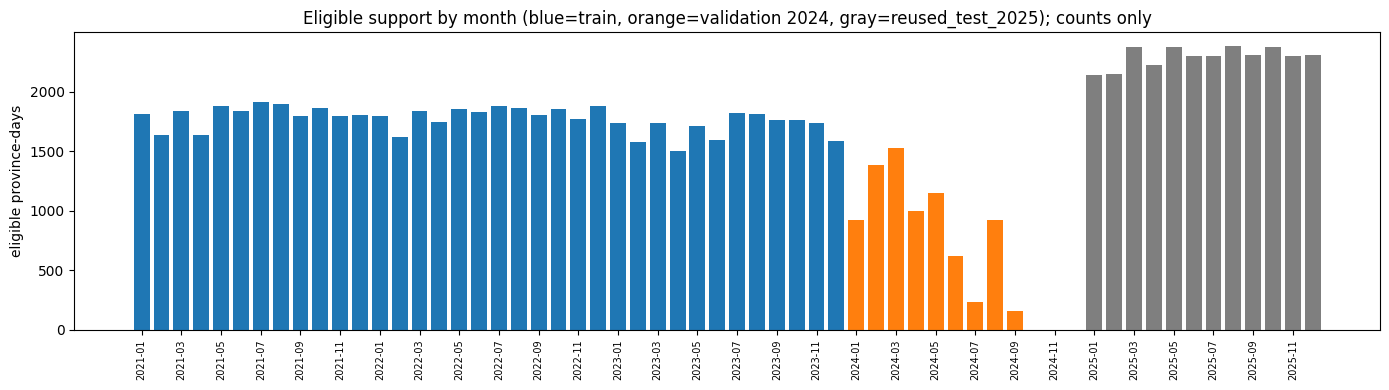

eligible rows by split: {'train': 63757, 'validation': 7885, 'reused_test_2025': 27506}
months with zero eligible rows: [['validation', '2024-10'], ['validation', '2024-11'], ['validation', '2024-12']]


,split,month,role_in_06,panel_rows,eligible_rows,eligible_distinct_dates,eligible_target_sum,eligible_zero_rows,possibly_undercounted_rows,boundary_excluded_rows
36,validation,2024-01,later_year_not_scored_in_06,2387,919,12,732,495,1468,0
37,validation,2024-02,later_year_not_scored_in_06,2233,1380,18,1106,774,853,0
38,validation,2024-03,later_year_not_scored_in_06,2387,1529,20,1319,813,858,0
39,validation,2024-04,later_year_not_scored_in_06,2310,994,13,916,526,1316,0
40,validation,2024-05,later_year_not_scored_in_06,2387,1149,15,946,646,1238,0
41,validation,2024-06,later_year_not_scored_in_06,2310,615,8,370,385,1695,0
42,validation,2024-07,later_year_not_scored_in_06,2387,229,3,143,142,2158,0
43,validation,2024-08,later_year_not_scored_in_06,2387,917,12,538,580,1470,0
44,validation,2024-09,later_year_not_scored_in_06,2310,153,2,98,96,2157,0
45,validation,2024-10,later_year_not_scored_in_06,2387,0,0,0,0,2387,0


In [5]:
support = support_by_split_month(panel, SPLITS, XCFG['folds'], TRAIN)
support.to_csv(REP / 'support_by_split_month.csv', index=False)
fig, ax = plt.subplots(figsize=(14, 4))
xs = np.arange(len(support))
colors = support['split'].map({'train': 'tab:blue', 'validation': 'tab:orange'}).fillna('tab:gray')
ax.bar(xs, support['eligible_rows'], color=colors)
ax.set_xticks(xs[::2])
ax.set_xticklabels(support['month'].iloc[::2], rotation=90, fontsize=7)
ax.set_ylabel('eligible province-days')
ax.set_title('Eligible support by month (blue=train, orange=validation 2024, gray=reused_test_2025); counts only')
fig.tight_layout()
fig.savefig(REP / 'support_by_split_month.png', dpi=110)
plt.show()
print('eligible rows by split:', support.groupby('split', sort=False)['eligible_rows'].sum().to_dict())
print('months with zero eligible rows:', support.loc[support['eligible_rows'] == 0, ['split', 'month']].values.tolist())
support[support['split'] != TRAIN]

## 3. Backtest ตามเวลา 4 fold ภายใน Train

แต่ละ fold fit ด้วยแถว eligible ที่ป้ายกำกับสิ้นสุด (`target_end`) ไม่เกินเวลาออกพยากรณ์แรก (18:00 วันก่อนวันเริ่มประเมิน) ดังนั้นวันสุดท้ายก่อนช่วงประเมินจะไม่อยู่ในชุด fit ฟังก์ชัน `build_temporal_folds` จะ raise ถ้ามี key ซ้ำหรือป้ายกำกับข้ามขอบ — นี่ตรวจขอบป้ายกำกับเท่านั้น **ไม่ได้** พิสูจน์ว่าข้อมูลถูกเผยแพร่ทันในอดีต

In [6]:
FOLDS = build_temporal_folds(COH, XCFG['folds'], FC['issue_hour_local'], FC['issue_days_before_target'], TZ)
fold_defs = fold_summary(FOLDS)
fold_defs.to_csv(REP / 'fold_definitions.csv', index=False)
fold_defs

,fold,eval_start,eval_end,first_issue_time,n_fit_rows,fit_first_date,fit_last_date,fit_max_target_end,n_eval_rows,eval_first_date,eval_last_date,eval_distinct_dates
0,1,2022-01-01,2022-06-30,2021-12-31T18:00:00+07:00,21622,2021-01-01,2021-12-30,2021-12-31T00:00:00+07:00,10675,2022-01-01,2022-06-30,179
1,2,2022-07-01,2022-12-31,2022-06-30T18:00:00+07:00,32297,2021-01-01,2022-06-29,2022-06-30T00:00:00+07:00,11057,2022-07-01,2022-12-31,184
2,3,2023-01-01,2023-06-30,2022-12-31T18:00:00+07:00,43354,2021-01-01,2022-12-30,2022-12-31T00:00:00+07:00,9855,2023-01-01,2023-06-30,174
3,4,2023-07-01,2023-12-31,2023-06-30T18:00:00+07:00,53211,2021-01-01,2023-06-29,2023-06-30T00:00:00+07:00,10471,2023-07-01,2023-12-29,176


In [7]:
t0 = time.perf_counter()
oof, fit_log = run_backtest(COH, FOLDS, SPECS, XCFG['encoding'], FEATURES, XCFG['threads'], log=lambda m: print(m, flush=True))
BACKTEST_SECONDS = round(time.perf_counter() - t0, 1)
validate_oof_scope(oof, XCFG['folds'], TRAIN)
assert len(oof) == int(fold_defs['n_eval_rows'].sum())
oof.assign(target_date=oof['target_date'].dt.strftime('%Y-%m-%d')).to_csv(MODEL_DATA / 'oof_predictions.csv', index=False)
OOF_SHA = sha256_file(MODEL_DATA / 'oof_predictions.csv')
print('backtest seconds:', BACKTEST_SECONDS, '| OOF rows:', len(oof), '| oof_predictions sha256:', OOF_SHA)
status_table = fit_log.pivot(index='spec_id', columns='fold', values='status').reindex([s['id'] for s in SPECS])
display(status_table)
warn = fit_log[(fit_log['n_warnings'] > 0) | fit_log['error'].notna()]
print('fits with warnings/errors:', len(warn))
warn[['fold', 'spec_id', 'status', 'n_iter', 'warnings', 'error']]

fold 1 baseline_zero                    ok                0.0s


fold 1 baseline_global_mean             ok                0.0s


fold 1 baseline_province_mean           ok                0.0s


fold 1 baseline_province_weekday_k10    ok                0.0s


fold 1 poisson_alpha_1e-4               ok                0.3s


fold 1 poisson_alpha_1e-2               ok                0.1s


... (38 outputs left out)

backtest seconds: 26.5 | OOF rows: 42058 | oof_predictions sha256: d884fe6751812afdc8dea535e638c3e7fb86415cfb3c6eb956e35f1381a98fb3


fold,1,2,3,4
spec_id,,,,
baseline_zero,ok,ok,ok,ok
baseline_global_mean,ok,ok,ok,ok
baseline_province_mean,ok,ok,ok,ok
baseline_province_weekday_k10,ok,ok,ok,ok
poisson_alpha_1e-4,ok,ok,ok,ok
poisson_alpha_1e-2,ok,ok,ok,ok
poisson_alpha_1e0,ok,ok,ok,ok
rf_t80_d12_l64_m50,ok,ok,ok,ok
rf_t120_d16_l128_m100,ok,ok,ok,ok


fits with warnings/errors: 0


,fold,spec_id,status,n_iter,warnings,error


## 4. Metric บน OOF (เซลล์เดียวกันทุกวิธี)

Primary = mean Poisson deviance (ถ่วงน้ำหนักเท่ากันทุกแถว) โดย floor ค่าทำนายที่ 1e-9 **เฉพาะ** ตอนคำนวณ deviance และบันทึกจำนวนแถวที่ถูก floor; MAE/RMSE/bias ใช้ค่าทำนายดิบ; Zero baseline มี deviance = null (ศูนย์อยู่นอกโดเมน) ไม่ใช้ Accuracy/MAPE

In [8]:
oof_m = oof_metrics_table(oof, SPECS, fit_log, XCFG['folds'], FLOOR, TRAIN)
fold_m = fold_metrics_table(oof, SPECS, fit_log, FLOOR)
monthly_m = grouped_metrics(oof.assign(month=oof['target_date'].dt.strftime('%Y-%m')), SPECS, ['fold', 'month'], FLOOR)
oof_m.to_csv(REP / 'oof_metrics.csv', index=False)
fold_m.to_csv(REP / 'fold_metrics.csv', index=False)
monthly_m.to_csv(REP / 'oof_monthly_metrics.csv', index=False)
fit_log.to_csv(REP / 'fit_log_backtest.csv', index=False)  # includes fit_seconds (runtime, nondeterministic)
display(fold_m.pivot(index='spec_id', columns='fold', values='mean_poisson_deviance').reindex([s['id'] for s in SPECS]))
oof_m.sort_values(['mean_poisson_deviance', 'spec_id'], na_position='last')[
    ['spec_id', 'family', 'eligible', 'mean_poisson_deviance', 'n_floored_for_deviance', 'mae', 'rmse', 'bias', 'wape',
     'observed_total', 'predicted_total', 'n_rows', 'ineligible_reason']]

fold,1,2,3,4
spec_id,,,,
baseline_zero,NaN,NaN,NaN,NaN
baseline_global_mean,1.607122,1.535315,1.542271,1.422478
baseline_province_mean,1.208710,1.147640,1.089684,0.998771
baseline_province_weekday_k10,1.231461,1.151555,1.096542,1.003153
poisson_alpha_1e-4,0.968178,0.982981,0.926089,0.867444
poisson_alpha_1e-2,1.138814,1.136209,1.118790,1.050216
poisson_alpha_1e0,1.592107,1.522719,1.529282,1.411256
rf_t80_d12_l64_m50,1.121823,1.095483,1.089821,1.008723
rf_t120_d16_l128_m100,1.134647,1.063713,1.091468,0.995913


,spec_id,family,eligible,mean_poisson_deviance,n_floored_for_deviance,mae,rmse,bias,wape,observed_total,predicted_total,n_rows,ineligible_reason
4,poisson_alpha_1e-4,poisson,True,0.937128,0.0,0.566542,0.924270,-0.028822,0.974624,24448.0,23235.783662,42058,None
9,hgb_i120_l15_m50_r1,hist_gradient_boosting,True,0.974299,0.0,0.563377,0.909010,-0.039397,0.969180,24448.0,22791.034960,42058,None
10,hgb_i160_l31_m100_r5,hist_gradient_boosting,True,1.016007,0.0,0.561516,0.916279,-0.046428,0.965978,24448.0,22495.338012,42058,None
8,rf_t120_d16_l128_m100,random_forest,True,1.071341,0.0,0.615353,0.943337,-0.024349,1.058594,24448.0,23423.944219,42058,None
7,rf_t80_d12_l64_m50,random_forest,True,1.079241,0.0,0.619506,0.944082,-0.028161,1.065739,24448.0,23263.615889,42058,None
5,poisson_alpha_1e-2,poisson,True,1.111379,0.0,0.652246,0.979571,-0.019078,1.122062,24448.0,23645.622962,42058,None
2,baseline_province_mean,baseline,True,1.112497,0.0,0.620184,0.963276,-0.016527,1.066905,24448.0,23752.897869,42058,None
3,baseline_province_weekday_k10,baseline,True,1.121998,0.0,0.621020,0.964514,-0.016201,1.068343,24448.0,23766.603451,42058,None
6,poisson_alpha_1e0,poisson,True,1.514118,0.0,0.768968,1.136677,-0.010943,1.322860,24448.0,23987.749914,42058,None
1,baseline_global_mean,baseline,True,1.527078,0.0,0.771578,1.139945,-0.010870,1.327350,24448.0,23990.818726,42058,None


## 5. เลือกและล็อกผล (จาก OOF เท่านั้น)

กฎ (ตามโปรโตคอล): config ดีที่สุดต่อตระกูล = deviance OOF ต่ำสุด (เสมอ → spec_id); selected candidate = ต่ำสุดข้ามตระกูล (เสมอ → Poisson > RF > HGB > spec_id) และต้องเป็นหนึ่งในสามตระกูลเสมอ; baseline ที่แข็งที่สุด = deviance ต่ำสุดในกลุ่ม baseline ที่ deviance นิยามได้ (ไม่รวม zero) ผู้สมัครจะเป็น **recommended reference** ได้ก็ต่อเมื่อผ่านทุกเกณฑ์: deviance ดีขึ้น ≥ 1%, MAE ≤ baseline × 1.02, ดีขึ้น ≥ 3 ใน 4 fold และขอบบน 95% ของ paired block bootstrap (7 วันปฏิทิน, 500 รอบ, seed 42) ของผลต่าง deviance < 0 ไม่เช่นนั้น baseline ยังเป็น reference — bootstrap เป็นการสำรวจและไม่ได้ปรับสำหรับการเลือกโมเดล

In [9]:
SEL = select_models(oof_m, XCFG['family_tie_order'])
assert SEL['selected_family'] in XCFG['family_tie_order']
pairs = [(SEL['best_per_family'][f], SEL['best_baseline']) for f in XCFG['family_tie_order']]
boot_rows = bootstrap_comparisons(oof, pairs, FLOOR, XCFG['bootstrap'])
pd.DataFrame(boot_rows).to_csv(REP / 'bootstrap_comparison.csv', index=False)
write_json(REP / 'bootstrap_comparison.json', {'evaluation_scope': OOF_SCOPE, 'params': XCFG['bootstrap'],
           'note': 'exploratory; paired moving-block bootstrap over calendar days; not adjusted for model selection',
           'comparisons': boot_rows})
sel_boot = next(r for r in boot_rows if r['candidate'] == SEL['selected_candidate'])
GATE = decision_gate(SEL['selected_candidate'], SEL['best_baseline'], oof_m, fold_m, sel_boot, XCFG['decision_gate'])
LOCK = build_selection_lock(SEL, GATE, oof_m, CONTRACT, OOF_SHA, SOURCE['functions_cell_sha256'], XCFG['family_tie_order'])
write_json(REP / 'selection_lock.json', LOCK)
LOCK_FILE_SHA = sha256_file(REP / 'selection_lock.json')
verify_selection_lock(REP / 'selection_lock.json', LOCK['decision_sha256'])
print('best per family    :', SEL['best_per_family'])
print('selected candidate :', SEL['selected_candidate'], '(' + SEL['selected_family'] + ')')
print('best baseline      :', SEL['best_baseline'])
print('recommended reference:', GATE['recommended_reference'], '[' + GATE['recommended_reference_type'] + ']')
print('reasoning:', GATE['reasoning'])
print('selection lock decision sha256:', LOCK['decision_sha256'])
display(pd.DataFrame(GATE['criteria']).T)
pd.DataFrame(boot_rows)[['candidate', 'baseline', 'point_estimate', 'ci_low', 'ci_high', 'valid_replicates', 'n_calendar_days', 'n_days_zero_weight']]

best per family    : {'poisson': 'poisson_alpha_1e-4', 'random_forest': 'rf_t120_d16_l128_m100', 'hist_gradient_boosting': 'hgb_i120_l15_m50_r1'}
selected candidate : poisson_alpha_1e-4 (poisson)
best baseline      : baseline_province_mean
recommended reference: poisson_alpha_1e-4 [candidate]
reasoning: all gate criteria passed: the selected candidate becomes the recommended reference
selection lock decision sha256: 63aeb27230f9e439ecda7d6f07243510d7ff292c85d411eea6f45d8008ecc787


,value,rule,passed,n_folds
relative_deviance_improvement,0.157635,>= 0.01,True,NaN
mae_ratio_candidate_over_baseline,0.913506,<= 1.02,True,NaN
folds_with_lower_deviance,4,>= 3,True,4
bootstrap_ci_upper_deviance_difference,-0.09267,< 0,True,NaN


,candidate,baseline,point_estimate,ci_low,ci_high,valid_replicates,n_calendar_days,n_days_zero_weight
0,poisson_alpha_1e-4,baseline_province_mean,-0.175369,-0.235342,-0.092670,500,728,15
1,rf_t120_d16_l128_m100,baseline_province_mean,-0.041156,-0.107369,0.031373,500,728,15
2,hgb_i120_l15_m50_r1,baseline_province_mean,-0.138197,-0.216770,-0.058488,500,728,15


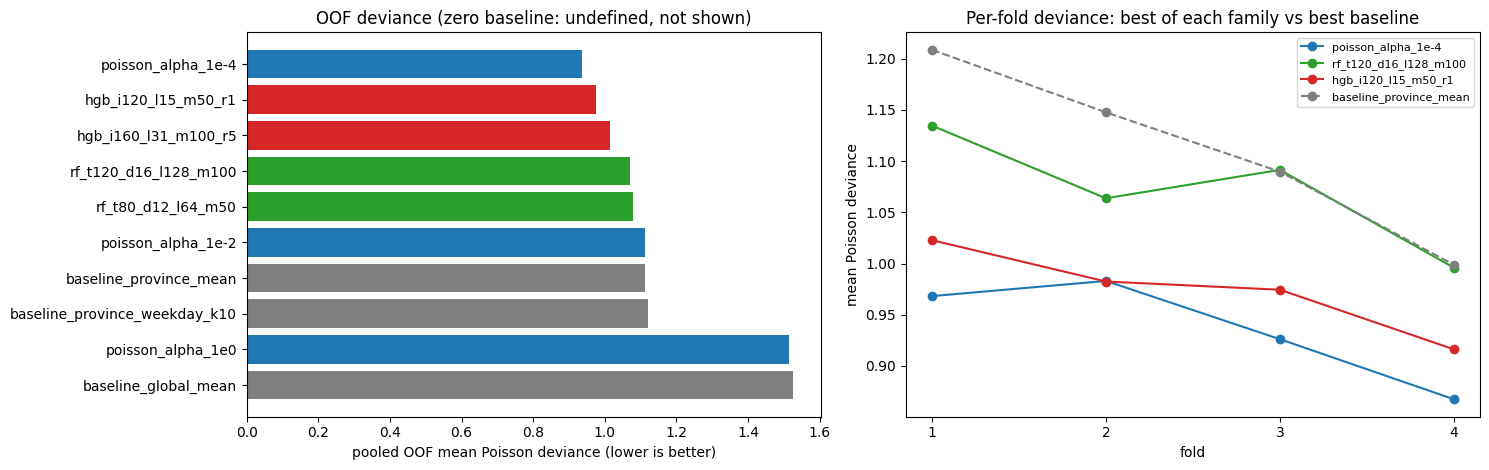

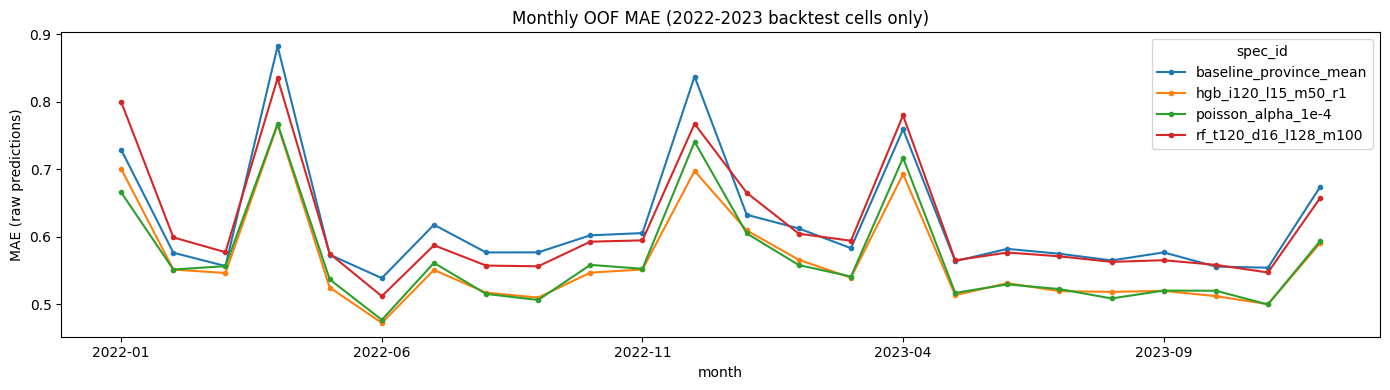

In [10]:
fam_color = {'baseline': 'tab:gray', 'poisson': 'tab:blue', 'random_forest': 'tab:green', 'hist_gradient_boosting': 'tab:red'}
pm = oof_m[oof_m['mean_poisson_deviance'].notna()].sort_values('mean_poisson_deviance')
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].barh(pm['spec_id'], pm['mean_poisson_deviance'], color=pm['family'].map(fam_color))
axes[0].invert_yaxis()
axes[0].set_xlabel('pooled OOF mean Poisson deviance (lower is better)')
axes[0].set_title('OOF deviance (zero baseline: undefined, not shown)')
show = list(SEL['best_per_family'].values()) + [SEL['best_baseline']]
fp = fold_m[fold_m['spec_id'].isin(show)].pivot(index='fold', columns='spec_id', values='mean_poisson_deviance')
for sid in show:
    fam = oof_m.set_index('spec_id').loc[sid, 'family']
    axes[1].plot(fp.index, fp[sid], marker='o', label=sid, color=fam_color[fam], linestyle='--' if fam == 'baseline' else '-')
axes[1].set_xticks(list(fp.index))
axes[1].set_xlabel('fold')
axes[1].set_ylabel('mean Poisson deviance')
axes[1].set_title('Per-fold deviance: best of each family vs best baseline')
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(REP / 'oof_deviance_by_spec_and_fold.png', dpi=110)
plt.show()
mm = monthly_m[monthly_m['spec_id'].isin(show)].pivot(index='month', columns='spec_id', values='mae')
ax = mm.plot(figsize=(14, 4), marker='.')
ax.set_ylabel('MAE (raw predictions)')
ax.set_title('Monthly OOF MAE (2022-2023 backtest cells only)')
plt.tight_layout()
plt.savefig(REP / 'oof_monthly_mae.png', dpi=110)
plt.show()

## 6. Fit ทุก configuration บน eligible Train ทั้งหมด (หลังล็อกแล้ว)

ใช้แถวเดียวกับ cohort ด้านบน (Train 2021–2023 ที่ eligible) ไม่มีการเพิ่มข้อมูลหรือเปลี่ยนพารามิเตอร์ บันทึก `data/model/bundles/<spec_id>.joblib` (sklearn Pipeline หรือ state ของ baseline + metadata แบบ dict ธรรมดา) แล้วโหลดกลับมาทำนายเทียบค่าเดิม Notebook นี้ **ไม่** ให้คะแนนปี 2024/2025

In [11]:
final_rows = []
for spec in SPECS:
    b = fit_bundle(spec, X_TRAIN, Y_TRAIN, XCFG['encoding'], XCFG['threads'], FEATURES)
    info = b['fit_info']
    row = {'spec_id': spec['id'], 'family': spec['family'], 'status': info['status'], 'converged': info['converged'], 'n_iter': info['n_iter'],
           'n_train_rows': info['n_train_rows'], 'n_warnings': len(info['warnings']), 'warnings': ' | '.join(info['warnings']), 'error': info['error'],
           'fit_seconds': info['fit_seconds'], 'bundle_path': None, 'bundle_sha256': None, 'reload_predictions_identical': None,
           'train_prediction_fingerprint': None, 'train_predicted_total': None}
    if b['pipeline'] is not None or b['baseline_state'] is not None:
        path = BUNDLES / (spec['id'] + '.joblib')
        row['bundle_path'] = path.relative_to(OUT).as_posix()
        row['bundle_sha256'] = save_bundle(b, path)
        if info['status'] == 'ok':
            p_mem = predict_bundle(b, X_TRAIN)
            p_disk = predict_bundle(load_bundle(path, row['bundle_sha256']), X_TRAIN)
            row['reload_predictions_identical'] = bool(np.array_equal(p_mem, p_disk))
            row['train_prediction_fingerprint'] = prediction_fingerprint(p_mem)
            row['train_predicted_total'] = float(p_mem.sum())
    final_rows.append(row)
    print('full-train %-32s %-13s %7.1fs' % (spec['id'], info['status'], info['fit_seconds'] or 0.0), flush=True)
final_fit = pd.DataFrame(final_rows)
final_fit.to_csv(REP / 'fit_log_full_train.csv', index=False)  # includes fit_seconds (runtime, nondeterministic)
ok_final = final_fit[final_fit['status'] == 'ok']
assert ok_final['reload_predictions_identical'].all(), 'a reloaded bundle predicted differently'
for fam in XCFG['family_tie_order']:
    assert (ok_final['family'] == fam).any(), 'stage failed: no full-Train bundle fitted for family ' + fam
for sid in (SEL['selected_candidate'], SEL['best_baseline'], GATE['recommended_reference']):
    assert sid in set(ok_final['spec_id']), 'locked model ' + sid + ' failed to fit on full Train'
verify_selection_lock(REP / 'selection_lock.json', LOCK['decision_sha256'])
assert sha256_file(REP / 'selection_lock.json') == LOCK_FILE_SHA, 'selection lock file changed after full-Train fitting'
final_fit.drop(columns=['warnings', 'bundle_path'])

full-train baseline_zero                    ok                0.0s


full-train baseline_global_mean             ok                0.0s


full-train baseline_province_mean           ok                0.0s


full-train baseline_province_weekday_k10    ok                0.0s


full-train poisson_alpha_1e-4               ok                0.2s


full-train poisson_alpha_1e-2               ok                0.0s


... (2 outputs left out)

full-train rf_t120_d16_l128_m100            ok                7.4s


full-train hgb_i120_l15_m50_r1              ok                0.3s


full-train hgb_i160_l31_m100_r5             ok                0.4s


AssertionError: a reloaded bundle predicted differently

## 7. Manifest และสัญญาสำหรับ Notebook 07/08

`model_artifact_manifest.json` แยกไฟล์ที่คาดว่า **ผลเหมือนเดิมทุกครั้ง** (deterministic: CSV/JSON ของ metric, การเลือก, prediction fingerprint) ออกจากไฟล์ที่มีเวลา/พาธ/ไบต์ของ pickle/PNG (nondeterministic) เพื่อใช้เปรียบเทียบการรันซ้ำ

In [ ]:
DETERMINISTIC = ['data/model/oof_predictions.csv', 'reports/models/oof_metrics.csv', 'reports/models/fold_metrics.csv',
                 'reports/models/oof_monthly_metrics.csv', 'reports/models/fold_definitions.csv', 'reports/models/support_by_split_month.csv',
                 'reports/models/bootstrap_comparison.csv', 'reports/models/bootstrap_comparison.json', 'reports/models/selection_lock.json']
NONDETERMINISTIC = ['reports/models/fit_log_backtest.csv', 'reports/models/fit_log_full_train.csv', 'reports/models/support_by_split_month.png',
                    'reports/models/oof_deviance_by_spec_and_fold.png', 'reports/models/oof_monthly_mae.png']
files = [{'path': p, 'sha256': sha256_file(OUT / p), 'deterministic': True} for p in DETERMINISTIC]
files += [{'path': p, 'sha256': sha256_file(OUT / p), 'deterministic': False} for p in NONDETERMINISTIC]
bundles = records(final_fit[['spec_id', 'family', 'status', 'converged', 'bundle_path', 'bundle_sha256', 'train_prediction_fingerprint',
                             'reload_predictions_identical']])
NEXT_STAGE = {
    'load': 'exec the single # FUNCTIONS cell of backend/notebooks/06_baseline_candidate_models.ipynb and require its sha256 == source.functions_cell_sha256',
    'verify': ['verify_selection_lock(reports/models/selection_lock.json, decision_sha256) before and after scoring',
               'load_bundle(path, bundle_sha256) for every bundle; only status ok bundles are scored',
               'contract.data_inputs_sha256 must match the verified data root'],
    'score': 'predict_bundle(bundle, rows) on eligible validation / reused_test_2025 rows with feature_frame(rows, features); regression_metrics(..., deviance_domain from the spec)',
    'forbidden': ['refit or tune on 2024/2025', 'change selected_candidate / recommended_reference from later-year scores', 'use 2026 as labels'],
    'oof_predictions_columns': list(oof.columns),
    'bundle_keys': ['bundle_format', 'spec_id', 'family', 'kind', 'deviance_domain', 'params', 'features', 'threads', 'sklearn_version',
                    'pipeline', 'baseline_state', 'fit_info'],
}
write_json(REP / 'model_artifact_manifest.json', {
    'producer': '06_baseline_candidate_models', 'output_root_relative_paths': True, 'contract': CONTRACT, 'source': SOURCE,
    'selection_lock_decision_sha256': LOCK['decision_sha256'], 'oof_predictions_sha256': OOF_SHA,
    'files': files, 'bundles': bundles,
    'determinism_note': 'deterministic files and train_prediction_fingerprint should match across same-contract reruns; bundle pickle bytes, PNGs, fit seconds, timestamps and paths are excluded from that comparison'})
experiment_manifest('ok', {
    'features': FEATURES, 'cohort': XCFG['cohort'], 'n_train_eligible_rows': int(len(COH)), 'folds': records(fold_defs),
    'specs': SPECS, 'selection': {'selected_candidate': SEL['selected_candidate'], 'selected_family': SEL['selected_family'],
                                  'best_per_family': SEL['best_per_family'], 'best_baseline': SEL['best_baseline'],
                                  'recommended_reference': GATE['recommended_reference'], 'recommended_reference_type': GATE['recommended_reference_type'],
                                  'stable_gain': GATE['stable_gain'], 'decision_sha256': LOCK['decision_sha256']},
    'later_years_scored_in_06': False, 'next_stage_contract': NEXT_STAGE,
    'runtime_nondeterministic': {'backtest_seconds': BACKTEST_SECONDS, 'finished_utc': dt.datetime.now(dt.timezone.utc).isoformat()}})
print('wrote', REP / 'experiment_manifest.json')
print('wrote', REP / 'model_artifact_manifest.json')
pd.DataFrame(files)

In [ ]:
om = oof_m.set_index('spec_id')
def line(sid):
    r = om.loc[sid]
    dev = 'null' if pd.isna(r['mean_poisson_deviance']) else '%.4f' % r['mean_poisson_deviance']
    return '%-30s deviance=%s MAE=%.4f RMSE=%.4f bias=%+.4f' % (sid, dev, r['mae'], r['rmse'], r['bias'])
print('ACTUAL OOF RESULTS (pooled 2022-2023 backtest cells, research mode, production disabled)')
for fam, sid in SEL['best_per_family'].items():
    print(' best', fam.ljust(24), line(sid))
print(' best baseline'.ljust(30), line(SEL['best_baseline']))
print(' zero baseline'.ljust(30), line('baseline_zero'))
print('selected candidate:', SEL['selected_candidate'], '| recommended reference:', GATE['recommended_reference'], '(' + GATE['recommended_reference_type'] + ')')
print(GATE['reasoning'])

## สรุปและข้อจำกัด (อ่านคู่กับผลจริงด้านบน)

- ตัวเลขทั้งหมดมาจากการรันจริงในเซลล์ด้านบน; ผลที่ใช้เลือกมีเพียง OOF ของ 4 fold ในปี 2022–2023 และถูกล็อกใน `reports/models/selection_lock.json` ก่อน fit บน Train ทั้งหมด
- selected candidate เป็นหนึ่งในสามตระกูลเสมอ ส่วน recommended reference อาจยังเป็น baseline ถ้าไม่ผ่านเกณฑ์ความเสถียร — ดูคอลัมน์ `criteria` และ `reasoning`
- คะแนนอธิบายเฉพาะเซลล์ eligible (selection bias จาก `training_eligible`) ไม่ใช่ทุกจังหวัด-วันหรือทุกถนน และไม่ใช่การพยากรณ์ที่พร้อมใช้งานจริง
- ยังไม่มี lag, สภาพอากาศ, วันหยุด หรือการจราจร จึงไม่มีการอ้างผลของปัจจัยเหล่านั้น; ไม่มีความเสี่ยงรายบุคคล
- **สัญญาสำหรับ 07/08:** ดู `next_stage_contract` ใน `reports/models/experiment_manifest.json` — 07/08 ประเมินปี 2024/2025 ด้วย bundle ที่ล็อกไว้ ห้าม refit/ปรับพารามิเตอร์/เปลี่ยนผู้ชนะจากคะแนนปีหลัง และต้องตรวจ `decision_sha256` ก่อนและหลัง
- ความพร้อมของโมเดลจริง: **BLOCKED** (ไม่เปลี่ยนจาก data foundation)